# Gyroscope Benchmark

This notebook trains a **linear time-invariant (LTI)** state-space model,
**Affine LPV-LFR** models and **Nonlinear-LFR (NL-LFR)** models on the gyroscope data set, which is
loaded from `data/gyro_train.mat` and `data/gyro_val.mat`. No test data is available for this benchmark.

The measured scheduling signal is used differently per model class: the LTI and LPV models use the
`_lpv` data sets (one input, scheduling signal as exogenous signal `D`), the NL models use the `_nl`
data sets (the scheduling signal as a second input).

In [1]:
# Initialize JAX settings
import os

os.environ["JAX_PLATFORMS"] = "cpu"  # or "cuda"
import jax

jax.config.update("jax_enable_x64", True)  # enforce float64 usage
jax.config.update("jax_num_cpu_devices", 16)  # number of CPU threads

# Optional, machine-specific: pin the process to the performance cores.
PIN_TO_P_CORES = True
if PIN_TO_P_CORES:
    import psutil

    psutil.Process(os.getpid()).cpu_affinity(list(range(16)))

import jax.numpy as jnp
import scipy.io as sio
import identax as idx
from matplotlib import pyplot as plt

## 1. Load the gyroscope data

In [2]:
def load_gyro_lpv(path):
    """Load a gyroscope record with the first scheduling signal as exogenous signal D."""
    mat = sio.loadmat(path)
    return idx.iddata(
        jnp.asarray(mat["exp_u"]),
        jnp.asarray(mat["exp_y"]),
        D=jnp.asarray(mat["exp_p"][:, 0:1]),
    )


def lpv_to_nl(d):
    """Use the scheduling signal as a second input instead of as an exogenous signal."""
    return idx.iddata(jnp.hstack([d.U, d.D]), d.Y)


data_train_lpv = load_gyro_lpv("data/gyro_train.mat")
data_val_lpv = load_gyro_lpv("data/gyro_val.mat")
data_train_nl = lpv_to_nl(data_train_lpv)
data_val_nl = lpv_to_nl(data_val_lpv)

print(f"Shape of LPV training data:   U={data_train_lpv.U.shape}, Y={data_train_lpv.Y.shape}, D={data_train_lpv.D.shape}")
print(f"Shape of LPV validation data: U={data_val_lpv.U.shape}, Y={data_val_lpv.Y.shape}, D={data_val_lpv.D.shape}")
print(f"Shape of NL training data:    U={data_train_nl.U.shape}, Y={data_train_nl.Y.shape}")
print(f"Shape of NL validation data:  U={data_val_nl.U.shape}, Y={data_val_nl.Y.shape}")

Shape of LPV training data:   U=(10000, 1), Y=(10000, 1), D=(10000, 1)
Shape of LPV validation data: U=(30000, 1), Y=(30000, 1), D=(30000, 1)
Shape of NL training data:    U=(10000, 2), Y=(10000, 1)
Shape of NL validation data:  U=(30000, 2), Y=(30000, 1)


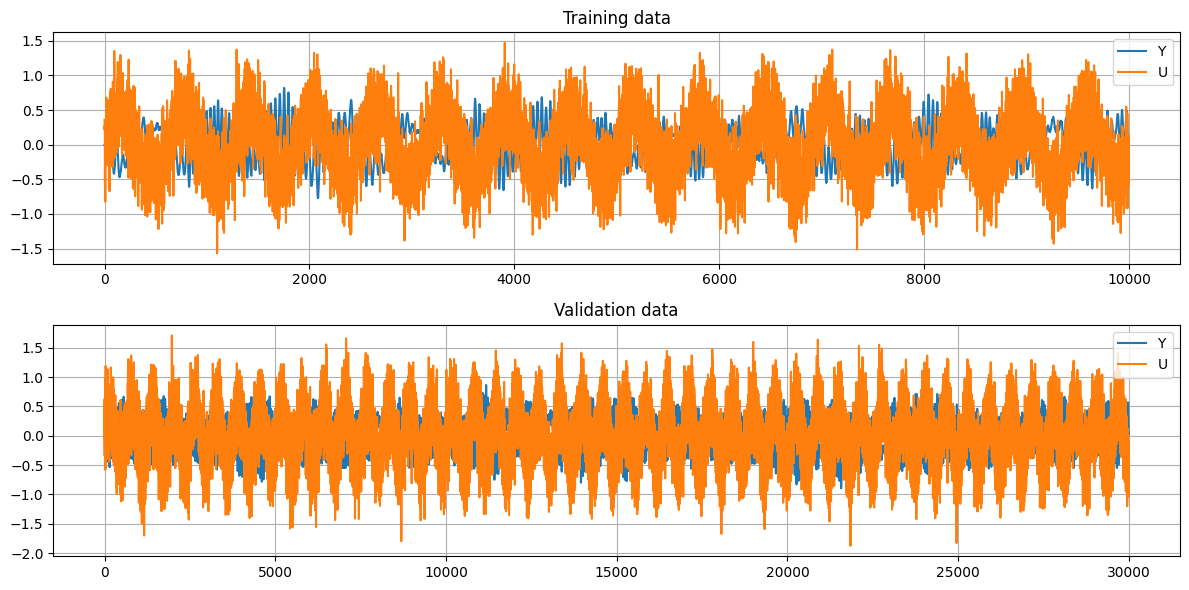

In [3]:
plot_sets = {"Training": data_train_lpv, "Validation": data_val_lpv}

fig, axs = plt.subplots(len(plot_sets), 1, figsize=(12, 6))
for ax, (title, d) in zip(axs, plot_sets.items()):
    ax.plot(d.Y, label="Y")
    ax.plot(d.U, label="U")
    ax.set_title(f"{title} data")
    ax.legend(loc="upper right")
    ax.grid()

plt.tight_layout()
plt.show()

## 2. Train an LTI state-space model

The LTI model serves as a baseline and as a warm start for the LPV models below.
The validation data is not used during training of any of the models in this notebook.

In [4]:
nu = 1
nu_nl = 2  # NL models: input and scheduling signal
ny = 1
nx = 5

key = jax.random.PRNGKey(42)  # same key for all models, for reproducibility

lti_cfg = idx.LinStateSpaceConfig(nx=nx, nu=nu, ny=ny)
lti_mod = idx.ModelLinStateSpace(lti_cfg, key)

optim_cfg_lti = idx.OptimConfig(adam_epochs=1000, lbfgs_epochs=1000, l2_rho=1e-3)

In [5]:
x0_init = jnp.zeros((nx,))
lti_mod, x0_train_lti, lti_history = idx.optimize(
    sys=lti_mod,
    train_data=data_train_lpv,
    x0=x0_init,
    config=optim_cfg_lti,
)

DataScaler not yet initialized, initializing using training data.


LTI validation BFR: 25.7


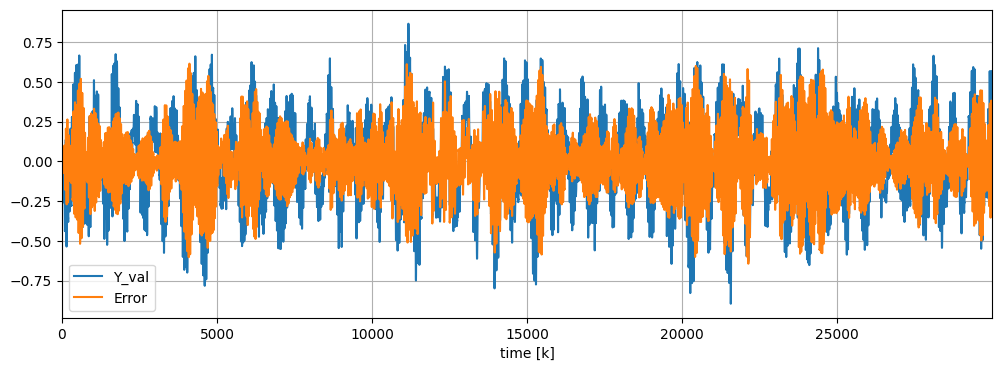

In [6]:
Yhat_val_lti, _ = lti_mod.simulate(data_val_lpv, x0_init)
BFR_val_lti = idx.metrics.BFR(data_val_lpv.Y, Yhat_val_lti)
print(f"LTI validation BFR: {BFR_val_lti[0]:.1f}")

plt.figure(figsize=(12, 4))
plt.plot(data_val_lpv.Y, label="Y_val")
plt.plot(data_val_lpv.Y - Yhat_val_lti, label="Error")
plt.xlabel("time [k]")
plt.autoscale(axis="x", tight=True)
plt.legend()
plt.grid()
plt.show()

## 3. Initialize and train Affine LPV-LFR models

The linear part of the LPV-LFR model is warm-started from the LTI model, after normalizing its
states using the simulated state trajectory on the training data. Two models are trained:
one with single shooting (simulation over the full training record) and one with
unconstrained multiple shooting (UMS), which splits the record into short sub-records.

In [7]:
# State normalization using the simulated state trajectory on the training data.
_, Xhat_train_lti = lti_mod.simulate(data_train_lpv, x0_init)
lti_scaled = idx.scale_lti_ss(lti_mod.A, lti_mod.B_u, lti_mod.C_y, lti_mod.D_yu, Xhat_train_lti)

# Configuration of the scheduling map
sched_cfg = idx.SchedulingMapConfig(layers=2, neurons_per_layer=6)

# Configuration of the LPV-LFR model
lpv_cfg = idx.AffineLPVLFRConfig(
    nx=nx,
    nu=nu,
    ny=ny,
    npar=3,                   # number of scheduling variables
    nreps=1,                  # number of repetitions per scheduling variable
    nd=1,                     # scheduling signal as exogenous input
    SchedulingMap=sched_cfg,
    StateEncoder=None,        # no state encoder is trained
    scalers="standard",
)

# Optimizer settings shared by the single-shooting LPV and NL-LFR models
optim_cfg_ss = idx.OptimConfig(
    adam_epochs=1000,
    lbfgs_epochs=20000,
    shooting_type="single",
    l2_rho=1e-4,     # add some L2 regularization
    grad_tol=1e-10,  # smaller tolerance than the default
)

# Optimizer settings shared by the UMS LPV and NL-LFR models
optim_cfg_ums = idx.OptimConfig(
    adam_epochs=1000,
    lbfgs_epochs=20000,
    shooting_type="multiple",  # use unconstrained multiple shooting
    T=200,                     # sub-record length of 200 samples
    l2_rho=1e-4,               # add some L2 regularization
    lbfgs_max_ls=20,
    grad_tol=1e-10,            # smaller tolerance than the default
)

### Single shooting

In [8]:
aff_mod = idx.ModelAffineLPVLFR(lpv_cfg, key, init_sys=lti_scaled)

aff_mod, x0_train_aff, aff_history = idx.optimize(
    aff_mod,
    data_train_lpv,
    x0_init,
    optim_cfg_ss,
)

DataScaler not yet initialized, initializing using training data.


### Unconstrained multiple shooting

In [9]:
aff_mod_ums = idx.ModelAffineLPVLFR(lpv_cfg, key, init_sys=lti_scaled)

aff_mod_ums, x0_train_aff_ums, aff_history_ums = idx.optimize(
    aff_mod_ums,
    data_train_lpv,
    x0_init,
    optim_cfg_ums,
)

DataScaler not yet initialized, initializing using training data.


## 4. Initialize and train Nonlinear-LFR models

The NL-LFR models have two inputs (input and scheduling signal), so they are warm-started from a
separately trained LTI model with two inputs. They use the same optimizer settings as the LPV models.
After initialization, the latent signals are rescaled to the training data.

In [10]:
lti_cfg_nl = idx.LinStateSpaceConfig(nx=nx, nu=nu_nl, ny=ny)
lti_mod_nl = idx.ModelLinStateSpace(lti_cfg_nl, key)

lti_mod_nl, x0_train_lti_nl, lti_history_nl = idx.optimize(
    sys=lti_mod_nl,
    train_data=data_train_nl,
    x0=x0_init,
    config=optim_cfg_lti,
)

# State normalization using the simulated state trajectory on the training data.
_, Xhat_train_lti_nl = lti_mod_nl.simulate(data_train_nl, x0_init)
lti_scaled_nl = idx.scale_lti_ss(lti_mod_nl.A, lti_mod_nl.B_u, lti_mod_nl.C_y, lti_mod_nl.D_yu, Xhat_train_lti_nl)

nllfr_cfg = idx.NLLFRConfig(
    nx=nx,
    nu=nu_nl,
    ny=ny,
    nw=3,
    nz=3,
    DeltaMap=idx.NetworkConfig(neurons_per_layer=6, clip=False),
    StateEncoder=None,
    scalers="standard",
)

DataScaler not yet initialized, initializing using training data.


### Single shooting

In [11]:
nllfr_mod = idx.ModelNLLFR(nllfr_cfg, key, init_sys=lti_scaled_nl)
nllfr_mod = nllfr_mod.rescale(data_train_nl)  # scale latent signals to training data

nllfr_mod, x0_train_nllfr, nllfr_history = idx.optimize(
    nllfr_mod,
    data_train_nl,
    x0_init,
    optim_cfg_ss,
)

### Unconstrained multiple shooting

In [12]:
nllfr_mod_ums = idx.ModelNLLFR(nllfr_cfg, key, init_sys=lti_scaled_nl)
nllfr_mod_ums = nllfr_mod_ums.rescale(data_train_nl)  # scale latent signals to training data

nllfr_mod_ums, x0_train_nllfr_ums, nllfr_history_ums = idx.optimize(
    nllfr_mod_ums,
    data_train_nl,
    x0_init,
    optim_cfg_ums,
)

## 5. Evaluate the models

Each model is evaluated on the data sets matching its input structure. For each data set the
initial state is first estimated, after which the best fit ratio (BFR) of the simulation is computed.

In [13]:
datasets_lpv = {"train": data_train_lpv, "val": data_val_lpv}
datasets_nl = {"train": data_train_nl, "val": data_val_nl}

# model name -> (trained model, training history, matching data sets)
trained = {
    "LTI": (lti_mod, lti_history, datasets_lpv),
    "LTI (2 inputs)": (lti_mod_nl, lti_history_nl, datasets_nl),
    "Affine LPV-LFR": (aff_mod, aff_history, datasets_lpv),
    "Affine LPV-LFR (UMS)": (aff_mod_ums, aff_history_ums, datasets_lpv),
    "NL-LFR": (nllfr_mod, nllfr_history, datasets_nl),
    "NL-LFR (UMS)": (nllfr_mod_ums, nllfr_history_ums, datasets_nl),
}

results = {}
for model_name, (model, _, model_datasets) in trained.items():
    results[model_name] = {}
    for name, d in model_datasets.items():
        x0, _ = idx.learn_initial_state(model, d, x0_init, lbfgs_epochs=1000, T=500, l2_rho=1e-3)
        Yhat, _ = model.simulate(d, x0)
        bfr = idx.metrics.BFR(d.Y, Yhat)
        results[model_name][name] = (Yhat, bfr)

# Print the BFR [%] per model and data set, and the training time.
print(f"{'BFR [%]':22s}" + "".join(f"{name:>10s}" for name in datasets_lpv) + f"{'time [s]':>10s}")
for model_name, model_results in results.items():
    bfrs = "".join(f"{model_results[name][1][0]:10.3f}" for name in datasets_lpv)
    print(f"{model_name:22s}{bfrs}{trained[model_name][1].total_time:10.1f}")

BFR [%]                    train       val  time [s]
LTI                       35.512    25.727       1.7
LTI (2 inputs)            36.354    25.130       1.7
Affine LPV-LFR            97.625    96.220      50.1
Affine LPV-LFR (UMS)      97.129    96.377      76.3
NL-LFR                    97.032    95.761      45.9
NL-LFR (UMS)              91.581    91.791      64.6


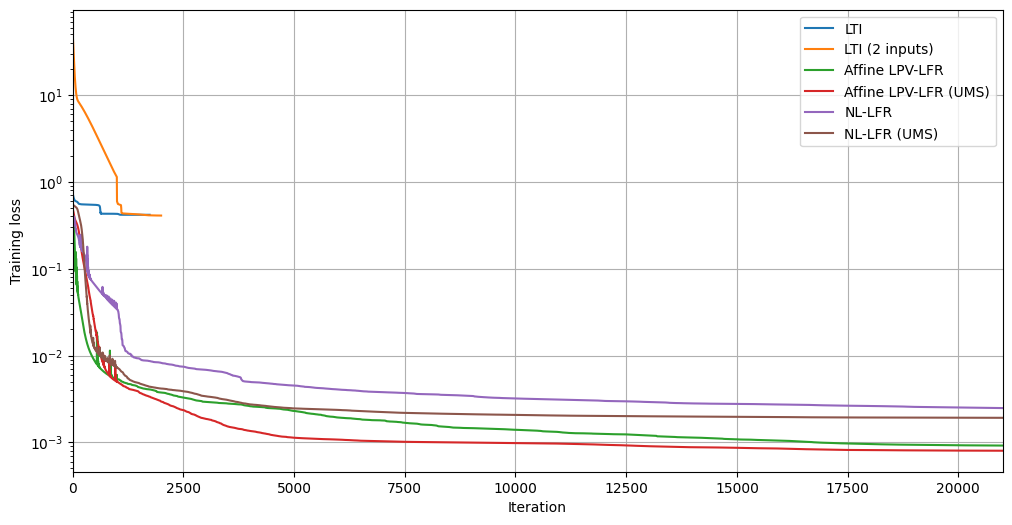

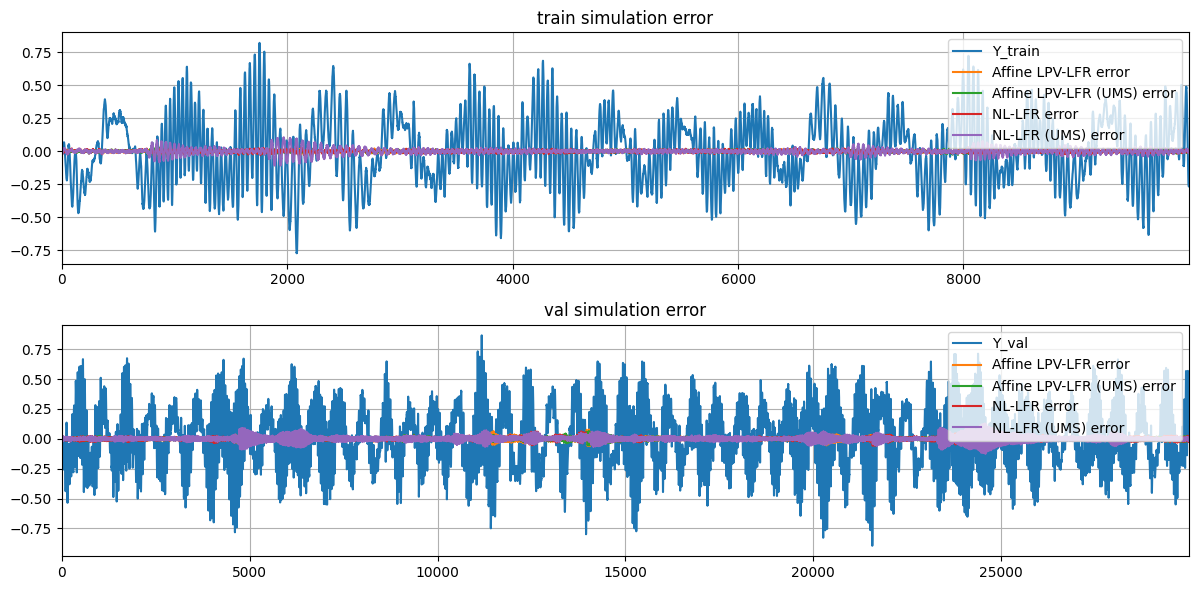

In [14]:
# Training loss of all models (no validation data is used during training).
plt.figure(figsize=(12, 6))
for model_name, (_, history, _) in trained.items():
    plt.semilogy(history.train, label=model_name)
plt.autoscale(axis="x", tight=True)
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.legend()
plt.grid()
plt.show()

# LTI is left out of the error plots: its error is expected to dwarf the others.
fig, axs = plt.subplots(len(datasets_lpv), 1, figsize=(12, 3 * len(datasets_lpv)))
for ax, (name, d) in zip(axs, datasets_lpv.items()):
    ax.plot(d.Y, label=f"Y_{name}")
    for model_name, model_results in results.items():
        if model_name.startswith("LTI"):
            continue
        ax.plot(d.Y - model_results[name][0], label=f"{model_name} error")
    ax.set_title(f"{name} simulation error")
    ax.autoscale(axis="x", tight=True)
    ax.legend(loc="upper right")
    ax.grid()

plt.tight_layout()
plt.show()